# 05 · Sensitivity — does the result survive the choices nobody measured?

Three settings in `evaluate.py` are modelling choices rather than
measurements: the stakeholder weight spread, the shortlist length, and the
fitted GP prior. A result that holds only at the values we happened to pick
is a result about those values.

`W_SPREAD` is the one with no path to resolution. The criterion acts on
*disagreement* between stakeholders, and that constant sets how much
disagreement exists. Near zero the stakeholders agree, so a
disagreement-targeting rule has nothing to target and should collapse toward
its own ablation; very large and every shortlist is uncertain, so the signal
may drown. No elicited preference data from mission planners exists, so
unlike the spatial prior it cannot be fitted — only surveyed.

The reported quantity throughout is the **paired margin in Precision@K over
the ablation**, because that is the comparison the inventive step rests on:
same posterior variance, same spatial propagation, blind only to shortlist
structure.

Four axes, 24 settings. This notebook also carries two results that belong
beside them — the negative control, which asks whether the margin survives
destroying the spatial structure the criterion exploits, and the technical
effect measured against shortlist length, since K is the one axis with a real
dependence.

Read in order:

1. provenance — which run produced these numbers, under which priors
2. the four axes
3. where the tolerance boundaries actually lie
4. validation — the negative control and the K dependence
5. what this licenses, and what it does not

***Cell 1*** — setup and provenance:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from lunarec_style import INK, INK2, MUTED, SURFACE, GRID, SERIES, BLUES, bare

CUR = ROOT / "data" / "patches" / "current"
EVAL = ROOT / "results" / "evaluation"

f = CUR / "patches_C2_sensitivity.csv"
assert f.exists(), (
    f"{f.name} not found. It is written by:\n"
    "  python -u src\\sensitivity.py data\\patches\\current\\patches_C2.csv 20 150\n"
    "Until that run completes this notebook has no input."
)
S = pd.read_csv(f)

# Provenance first. Every row records the parameters in force when it was
# measured, so a sweep can never be ambiguous about which model produced it --
# an earlier generation of results was, and cost a day to disentangle.
mt = pd.Timestamp(f.stat().st_mtime, unit="s", tz="UTC").tz_convert("Asia/Kolkata")
print(f"{f.name}  ({f.stat().st_size/1024:.1f} KB, {mt:%Y-%m-%d %H:%M})")
print(f"scene    : {S.scene.unique()[0]}")
print(f"settings : {len(S)} across {S.axis.nunique()} axes")
print(f"reps     : {S.n_rep.unique()}   budget: {S.budget.unique()}")

base = S[(S.axis == "range_mult") & (S.setting == 1.0)]
if len(base):
    b = base.iloc[0]
    print("\nfitted priors (the operating point):")
    print(f"  ranges  {b.ranges.replace(';', ' / ')} m")
    print(f"  nuggets {b.nuggets.replace(';', ' / ')}")
    print(f"  margin here: {b.margin:+.3f}  ({b.wins}/{b.n_rep}, t = {b.t:.2f})")

print("\nsettings per axis:")
for a, g in S.groupby("axis"):
    print(f"  {a:<12} {len(g):2d}   {', '.join(str(x) for x in sorted(g.setting))}")

patches_C2_sensitivity.csv  (2.6 KB, 2026-11-01 01:23)
scene    : patches_C2
settings : 24 across 4 axes
reps     : [20]   budget: [150]

fitted priors (the operating point):
  ranges  2782 / 1902 / 2347 m
  nuggets 0.332 / 0.039 / 0.266
  margin here: +0.278  (20/20, t = 10.00)

settings per axis:
  K             5   5.0, 10.0, 20.0, 30.0, 50.0
  W_SPREAD      7   0.01, 0.03, 0.05, 0.07, 0.1, 0.15, 0.25
  nugget        6   0.0, 0.05, 0.15, 0.3, 0.45, 0.6
  range_mult    6   0.25, 0.5, 1.0, 2.0, 3.0, 4.0


***Cell 2*** — the four axes:

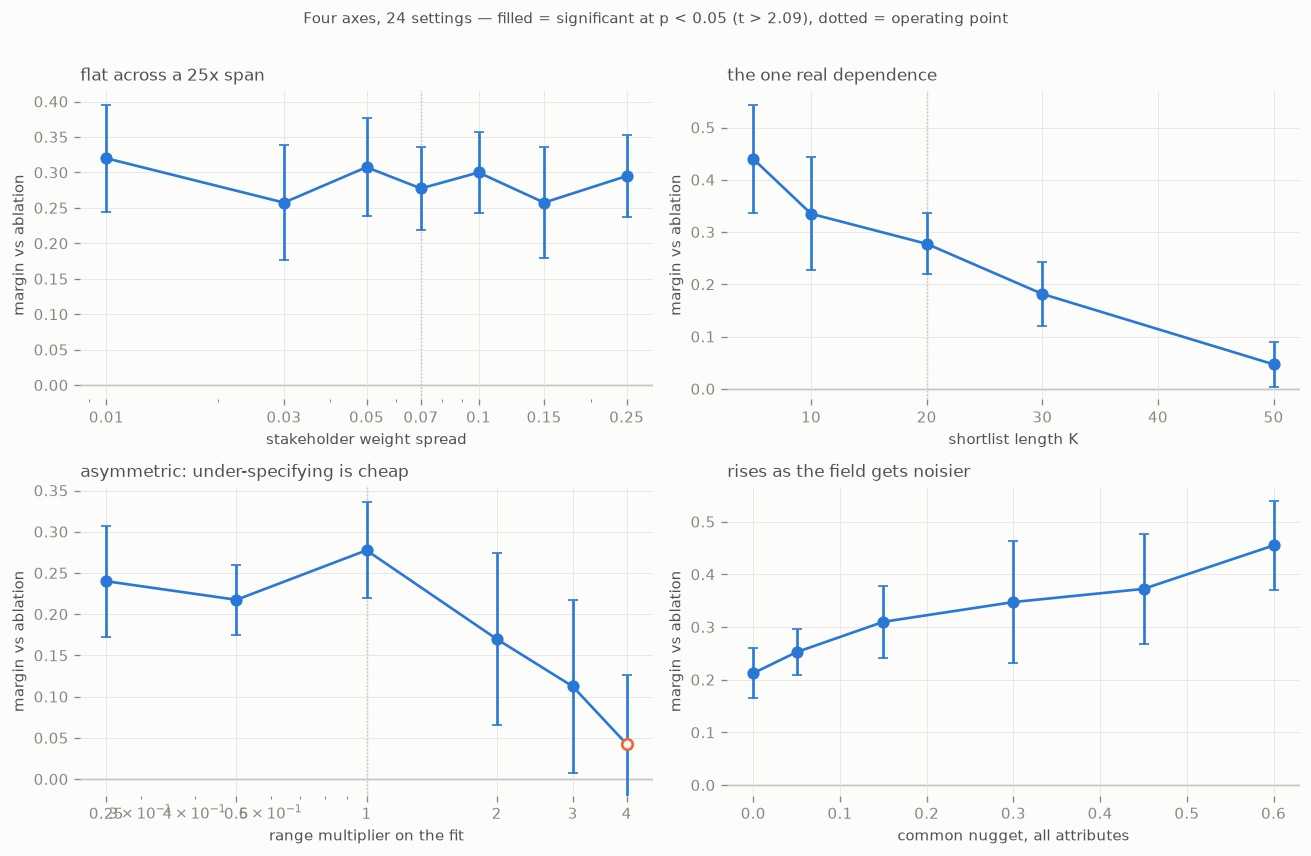

axis          setting   margin          95% CI    wins       t  significant
W_SPREAD         0.01    0.320[+0.244, +0.396]   19/20    8.85   yes
W_SPREAD         0.03    0.257[+0.176, +0.339]   18/20    6.64   yes
W_SPREAD         0.05    0.307[+0.238, +0.377]   19/20    9.29   yes
W_SPREAD         0.07    0.278[+0.219, +0.336]   20/20   10.00   yes
W_SPREAD          0.1    0.300[+0.243, +0.357]   20/20   11.05   yes
W_SPREAD         0.15    0.257[+0.179, +0.336]   19/20    6.85   yes
W_SPREAD         0.25    0.295[+0.237, +0.353]   20/20   10.69   yes
K                   5    0.440[+0.337, +0.543]   19/20    8.90   yes
K                  10    0.335[+0.227, +0.443]   18/20    6.51   yes
K                  20    0.278[+0.219, +0.336]   20/20   10.00   yes
K                  30    0.182[+0.121, +0.243]   17/20    6.23   yes
K                  50    0.047[+0.003, +0.091]   14/20    2.26   yes
range_mult       0.25    0.240[+0.173, +0.307]   18/20    7.46   yes
range_mult        0.5    0.

In [2]:
# Each axis holds the other three at the operating point and sweeps one. The
# reported quantity is the paired margin in Precision@K over the ablation.
#
# Error bars are recovered, not re-measured: sensitivity.py stores the paired
# t, and t = margin / SE, so SE = margin / t and the interval is t(19) x SE.
# Filled markers clear that threshold, hollow ones do not.
#
# CAVEAT on the nugget panel. The other three axes perturb a parameter around
# its fitted value, so the operating point sits somewhere on the line. The
# nugget sweep does not: it sets all three attributes to a COMMON nugget,
# while the fitted model has 0.332 / 0.039 / 0.266. There is therefore no
# x-value on that panel where the operating point lies, and the dotted
# reference line is omitted there. Re-running it as a multiplier on the fitted
# nuggets, the way range_mult works, is an open item.
from scipy.stats import t as tdist

FIGS = ROOT / "results" / "figures"; FIGS.mkdir(parents=True, exist_ok=True)
TCRIT = float(tdist.ppf(0.975, int(S.n_rep.iloc[0]) - 1))

PANELS = [
    ("W_SPREAD",   "stakeholder weight spread",      True,  0.07,
     "flat across a 25x span"),
    ("K",          "shortlist length K",             False, 20,
     "the one real dependence"),
    ("range_mult", "range multiplier on the fit",    True,  1.0,
     "asymmetric: under-specifying is cheap"),
    ("nugget",     "common nugget, all attributes",  False, None,
     "rises as the field gets noisier"),
]

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (key, xlabel, logx, op, title) in zip(axs.ravel(), PANELS):
    g = S[S.axis == key].sort_values("setting")
    x, y, tv = g.setting.values, g.margin.values, g.t.values
    ci = TCRIT * (y / tv)
    sig = tv > TCRIT

    ax.axhline(0, color=MUTED, lw=0.8, zorder=1)
    if op is not None:
        ax.axvline(op, color=MUTED, lw=0.8, ls=":", zorder=1)
    ax.errorbar(x, y, yerr=ci, color=SERIES[0], lw=1.6, capsize=3, zorder=2)
    ax.scatter(x[sig], y[sig], s=40, color=SERIES[0], zorder=3)
    ax.scatter(x[~sig], y[~sig], s=40, facecolors=SURFACE,
               edgecolors=SERIES[1], linewidths=1.6, zorder=3)

    if logx:
        ax.set_xscale("log")
        ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in x])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("margin vs ablation")
    ax.set_title(title, color=INK2, loc="left")
    ax.set_ylim(bottom=min(-0.02, y.min() - 0.05))
    bare(ax)

fig.suptitle("Four axes, 24 settings — filled = significant at p < 0.05 "
             f"(t > {TCRIT:.2f}), dotted = operating point",
             color=INK2, fontsize=9, y=1.01)
plt.tight_layout()
plt.savefig(FIGS / "05_four_axes.png", bbox_inches="tight")
plt.show()

print(f"{'axis':<12}{'setting':>9}{'margin':>9}{'95% CI':>16}{'wins':>8}"
      f"{'t':>8}  significant")
for key, _, _, _, _ in PANELS:
    for _, r in S[S.axis == key].sort_values("setting").iterrows():
        ci = TCRIT * (r.margin / r.t)
        print(f"{r.axis:<12}{r.setting:>9g}{r.margin:>9.3f}"
              f"{f'[{r.margin-ci:+.3f}, {r.margin+ci:+.3f}]':>16}"
              f"{f'{int(r.wins)}/{int(r.n_rep)}':>8}{r.t:>8.2f}"
              f"   {'yes' if r.t > TCRIT else 'NO'}")

ns = S[S.t <= TCRIT]
print(f"\n{len(S) - len(ns)} of {len(S)} settings significant at p < 0.05 "
      f"(uncorrected; these sweeps are exploratory, not in the confirmatory "
      f"family of 16).")
if len(ns):
    print("not significant:")
    for _, r in ns.iterrows():
        print(f"  {r.axis} = {r.setting:g}   margin {r.margin:+.3f}, "
              f"{int(r.wins)}/{int(r.n_rep)}, t = {r.t:.2f}")

print(f"\nfigure -> {FIGS / '05_four_axes.png'}")

***Cell 3*** — where the tolerance boundaries actually lie:

In [ ]:
# A sweep that never breaks is not a measured boundary. Three of the four axes
# are still significant at their most extreme setting, so for those the honest
# statement is "no edge found within the span tested", not "tolerated up to X".
# Only range_mult actually breaks, and this cell brackets where.
#
# The second half asks the question the sweep exists to answer: is the result
# stable across MORE than the parameters are uncertain by? That needs numbers
# from notebook 03, which are transcribed below rather than recomputed -- the
# fits behind them take minutes and belong to that notebook. Each carries the
# cell that produced it so it can be traced rather than trusted.

# --- from notebook 03, cell 26 (four directions, 4 km window) ---------------
ANISO_LONG  = (1.14, 2.36)   # long axis / isotropic fit, min and max of 12
ANISO_SHORT = (0.33, 0.82)   # short axis / isotropic fit
# --- from notebook 03, the three-estimator comparison ----------------------
EST_RANGE   = (0.49, 1.74)   # marginal likelihood vs Cressie, range ratio
EST_NUGDIFF = 0.354          # max |nugget difference| between estimators
FIT_NUGGETS = (0.039, 0.332) # the fitted nuggets themselves, C2 scene set

print("boundaries, per axis")
print(f"{'axis':<12}{'swept':>18}{'significant over':>20}   edge")
EDGES = {}
for key in ["W_SPREAD", "K", "range_mult", "nugget"]:
    g = S[S.axis == key].sort_values("setting")
    x, sig = g.setting.values, (g.t.values > TCRIT)
    lo, hi = x[sig].min(), x[sig].max()
    first_ns = x[~sig].min() if (~sig).any() else None
    if first_ns is None:
        edge = "NOT FOUND -- still significant at the end of the sweep"
    else:
        last_sig_below = x[sig & (x < first_ns)].max()
        edge = f"between {last_sig_below:g} and {first_ns:g}"
    EDGES[key] = (lo, hi, first_ns)
    print(f"{key:<12}{f'{x.min():g} to {x.max():g}':>18}"
          f"{f'{lo:g} to {hi:g}':>20}   {edge}")

print("\nOnly range_mult has a measured edge. For the other three the sweep ran")
print("out before the result did, so their spans are lower bounds on tolerance.")

# --- is the tolerance wider than the uncertainty? ---------------------------
print("\n" + "=" * 70)
print("tolerance against measured uncertainty")
print("=" * 70)

rng = S[S.axis == "range_mult"]
tol_hi = float(rng[rng.t > TCRIT].setting.max())
print(f"\nRANGE   tolerated 0.25x to {tol_hi:g}x "
      f"(breaks between {tol_hi:g}x and 4x)")
for lab, (a, b) in [("estimator disagreement", EST_RANGE),
                    ("directional long axis", (1.0, ANISO_LONG[1])),
                    ("directional short axis", (ANISO_SHORT[0], 1.0))]:
    inside = (a >= 0.25) and (b <= tol_hi)
    print(f"  {lab:<26} {a:.2f}x - {b:.2f}x   "
          f"{'inside' if inside else 'EXCEEDS the tolerated band'}")

nug = S[S.axis == "nugget"]
print(f"\nNUGGET  significant across the whole swept span "
      f"{nug.setting.min():g} to {nug.setting.max():g}, no edge found")
print(f"  fitted nuggets in use      {FIT_NUGGETS[0]:.3f} - {FIT_NUGGETS[1]:.3f}   inside")
print(f"  max estimator disagreement {EST_NUGDIFF:.3f}            inside")
print(f"  margin at the top of the sweep is {nug.margin.max():.3f}, "
      f"the LARGEST of the 24 -- it is still rising, not plateauing")

# --- figure ----------------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))

ax = axs[0]
BANDS = [("tolerated", 0.25, tol_hi, SERIES[0]),
         ("estimator disagreement", *EST_RANGE, SERIES[1]),
         ("directional spread", ANISO_SHORT[0], ANISO_LONG[1], SERIES[2])]
for i, (lab, a, b, col) in enumerate(BANDS):
    ax.plot([a, b], [i, i], lw=7, color=col, solid_capstyle="butt", alpha=.85)
    ax.text(b * 1.06, i, lab, va="center", fontsize=8, color=INK2)
ax.axvline(1.0, color=MUTED, lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlim(0.2, 12)
ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25x", "0.5x", "1x", "2x", "4x"])
ax.set_yticks([]); ax.set_ylim(-0.8, len(BANDS) - 0.2)
ax.set_xlabel("multiplier on the fitted range")
ax.set_title("Range: tolerance vs uncertainty", color=INK2, loc="left")
bare(ax)

ax = axs[1]
g = S[S.axis == "nugget"].sort_values("setting")
ax.errorbar(g.setting, g.margin, yerr=TCRIT * (g.margin / g.t),
            color=SERIES[0], lw=1.6, marker="o", ms=5, capsize=3)
ax.axvspan(FIT_NUGGETS[0], FIT_NUGGETS[1], color=SERIES[2], alpha=.15)
ax.text(np.mean(FIT_NUGGETS), ax.get_ylim()[0], " fitted", fontsize=8,
        color=INK2, va="bottom", ha="center")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("common nugget"); ax.set_ylabel("margin vs ablation")
ax.set_title("Nugget: no edge, and still rising", color=INK2, loc="left")
bare(ax)

plt.tight_layout()
plt.savefig(FIGS / "05_tolerance_vs_uncertainty.png", bbox_inches="tight")
plt.show()
print(f"\nfigure -> {FIGS / '05_tolerance_vs_uncertainty.png'}")